In [2]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [68]:
class CricketState(TypedDict):
    runs: int
    balls: int
    sixes: int
    fours: int
    strike_rate: float
    balls_by_boundry: float
    bounndry_percentage: float
    summary: str

In [69]:
def strike_rate(state : CricketState):

    sr = (state["runs"] / state["balls"]) * 100

    return {"strike_rate": sr} # partial state update

# The Reason we are partially updating the state is because we are not changing the entire state, we are only changing the strike rate. So we return a dictionary with only the strike rate. 

# node expects a dictionary and returns a dictionary. 

# Reason for using partial state update --> when we are passing entire state to the nodes parallelly, and passing the state by each node to the next node, the langgraph raises a conflict that (a state is being updated by multiple nodes at the same time) and it don't know which one is correct,so we are updating nodes partially.

In [70]:
def bpb(state: CricketState):

    bpb = state['balls'] / (state['sixes'] + state['fours'])

    return {"balls_by_boundry": bpb}

In [71]:
def boundry_percentage(state: CricketState):

    bp = ((state['sixes'] + state['fours']) / state['balls']) * 100

    return {"bounndry_percentage": bp}


In [72]:
def summary(state: CricketState):

    summary = f"""
    Strike Rate : {state['strike_rate']}
    Balls Per Boundary : {state['balls_by_boundry']}
    Boundary Percentage : {state['bounndry_percentage']}
    """

    return {"summary": summary}

In [81]:
graph = StateGraph(CricketState)

# add nodes to the graph
graph.add_node("strike_rate", strike_rate)
graph.add_node("bpb", bpb)
graph.add_node("boundry_percentage", boundry_percentage)
graph.add_node("summary", summary)

In [82]:
# add edges to the graph

graph.add_edge(START, "strike_rate")
graph.add_edge(START, "bpb")
graph.add_edge(START, "boundry_percentage")
graph.add_edge("strike_rate", "summary")
graph.add_edge("bpb", "summary")    
graph.add_edge("boundry_percentage", "summary")
graph.add_edge('summary', END)

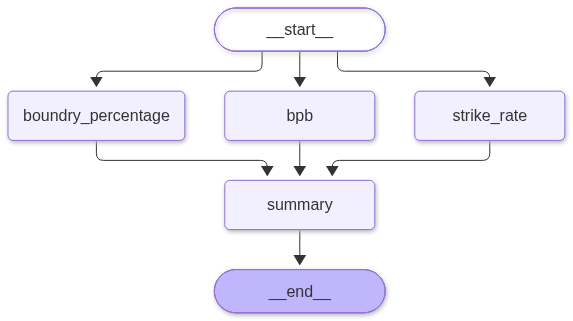

In [83]:
workflow = graph.compile()
workflow

In [84]:
initial_state = {
    "runs": 100,
    "balls": 60,
    "sixes": 5,
    "fours": 10
}

In [85]:
workflow.invoke(initial_state)

{'runs': 100,
 'balls': 60,
 'sixes': 5,
 'fours': 10,
 'strike_rate': 166.66666666666669,
 'balls_by_boundry': 4.0,
 'bounndry_percentage': 25.0,
 'summary': '\n    Strike Rate : 166.66666666666669\n    Balls Per Boundary : 4.0\n    Boundary Percentage : 25.0\n    '}